# マルコフ決定過程：収益から最適方策へ

『ゼロから作る Deep Learning ❹』第 2 章 2.3〜2.5 の輪読会資料

この回では目の前の報酬と将来まで含めた収益の違いを理解する。

2 マス分の範囲で方策を比較し、どの状態から始めても収益の期待値が高い方策を求める。

| 内容 | 目標 |
|---|---|
| 実行準備と MDP の復習 | 状態・行動・報酬を区別する |
| 2.3.1〜2.3.2：タスクと収益 | 割引した報酬の和を計算する |
| 2.3.3〜2.3.4：価値と最適性 | 期待値と「すべての状態」の意味を説明する |
| 2.4：2 マスの MDP | 4 通りの方策を手計算とコードで比較する |
| 2.5：まとめ | 収益・価値・最適方策を言葉で説明する |

## 実行の準備

In [1]:
# 初回の環境準備で使う。
# %pip install numpy pandas matplotlib ipython
# PyTorch も使用する場合は、次の行も有効にする。
# %pip install torch

In [2]:
import sys
import importlib.util
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
from IPython.display import display

# 小数の表示桁数をそろえる。計算に使う数値の精度は変わらない。
np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.precision", 6)

# 図中のラベルは短い英語にし、図の説明は日本語のテキストセルに記す。
# 日本語フォントがない環境でも、文字が欠けないようにするためである。
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2
})

COLORS = ["#1B6CA8", "#0A8F7A", "#D27D2D", "#955277"]
GAMMA = 0.9
HAS_TORCH = importlib.util.find_spec("torch") is not None
if HAS_TORCH:
    import torch

print("Python：", sys.version.split()[0])
print("NumPy：", np.__version__, " / pandas：", pd.__version__)
print("Matplotlib：", matplotlib.__version__)
print("PyTorch：", torch.__version__ if HAS_TORCH else "未導入")

Python： 3.11.15
NumPy： 1.23.5  / pandas： 2.3.3
Matplotlib： 3.10.9
PyTorch： 2.14.1+cpu


## 2.3 MDP の目標

### 復習：環境とエージェントが決めること

マルコフ決定過程 (Markov Decision Process：MDP) とは、状態を見て行動を選び報酬を受け取って次の状態へ進む問題の表し方である。  
将来の状態や報酬を考えるとき、現在の状態と行動が分かればそれ以前の履歴を別に調べなくてよい。この性質をマルコフ性という。  

| 記号 | 意味 | 2 マスのワールドにおける例 |
|---|---|---|
| $S_t$ | 時刻 $t$ の状態を表す確率変数 | 左のマスにいるか、右のマスにいるか |
| $s$ | 状態の具体的な値 | $L1$ |
| $A_t$、$a$ | 行動を表す確率変数と、その具体的な値 | 左へ移動する |
| $R_t$ | 時刻 $t$ の行動で得る報酬 | リンゴを得ると $+1$ |
| $p(s'\mid s,a)$ | 状態 $s$ で行動 $a$ を選んだとき、次が $s'$ になる確率 | 左から右へ動く確率 |
| $r(s,a,s')$ | その遷移で得る報酬 | 左から右へ動くと $+1$ |
| $\pi(a\mid s)$ | 状態 $s$ で行動 $a$ を選ぶ確率。方策と呼ぶ | 左右をそれぞれ確率 $1/2$ で選ぶ |

大文字の $S_t$ は、時刻 $t$ の状態を表す確率変数である。小文字の $s$ は、$L1$ や $L2$ など、$S_t$ が取りうる具体的な状態を表す。  
たとえば、時刻 $t$ に左のマスにいることは、$S_t=L1$ と書ける。決定論的な環境では、遷移先の確率が $1$、ほかが $0$ になる。  

環境が $p$ と $r$ を決め、エージェントが方策 $\pi$ に従って行動する。各状態で行動の確率を足すと $1$、各状態・行動で遷移先の確率を足しても $1$ になる。

$$
\sum_a\pi(a\mid s)=1,\qquad \sum_{s'}p(s'\mid s,a)=1.
$$

本資料では、教科書に合わせて $S_t$ で $A_t$ を選んだ直後の報酬を $R_t$ とする。(別の教科書では、直後の報酬を $R_{t+1}$ と書く場合もある)

$$
S_t\;\xrightarrow{\ A_t,\ R_t\ }\;S_{t+1}
\;\xrightarrow{\ A_{t+1},\ R_{t+1}\ }\;S_{t+2}.
$$

### 2.3.1 エピソードタスクと連続タスク

| 種類 | 終わり方 | 例 | 収益を計算する範囲 |
|---|---|---|---|
| エピソードタスク | 終了状態に到達する | 対局の終了、迷路のゴール | 開始から終了まで |
| 連続タスク | 終了状態を設けない | 継続する在庫管理、今回の 2 マスの世界 | 現在から無限の将来まで |

エピソードとは開始から終了までの一連のやり取りである。終了時刻が $T$ なら、最後の行動で受け取る報酬は $R_{T-1}$ になる。  

### 2.3.2 収益：将来の報酬をまとめる

報酬は各ステップで受け取る値である。収益 $G_t$ は時刻 $t$ 以降の報酬を割引して足した値である。  

$$
G_t=R_t+\gamma R_{t+1}+\gamma^2R_{t+2}+\cdots \tag{2.1}
$$

$\gamma$ は割引率である。$k$ ステップ先の報酬には $\gamma^k$ を掛ける。$\gamma^0=1$ なので、現在の報酬はそのまま足す。  
$\gamma=0.9$ なら、重みは $1,0.9,0.81,0.729,\ldots$ となる。割引率は連続タスクを想定したときに、収益が無限大になることを防ぐために導入される。  

以下では連続タスクについて $0\leq\gamma<1$ を仮定する。$\gamma$ が小さいほど近い報酬を重く見る。$\gamma=0$ では現在の報酬だけを評価する。

報酬に $[1,-1,2,0]$ をもつ 4 エピソードの短い例で確認する。`rewards` は報酬、`powers` は何ステップ先か、`weights` は割引の重みを格納する。配列どうしの `*` は同じ位置の要素どうしを掛ける。

$$
G_0^{(4)}=1+0.9\times(-1)+0.9^2\times2+0.9^3\times0=1.72.
$$

上付きの $(4)$ は最初の $4$ 個だけを足したことを示す。

In [3]:
# 説明用の報酬列。教科書の 2 マスの軌跡とは別の例である。
rewards = np.array([1.0, -1.0, 2.0, 0.0])
powers = np.arange(len(rewards))         # [0, 1, 2, 3]
weights = GAMMA ** powers                # [1, 0.9, 0.81, 0.729]
contributions = weights * rewards        # 各時刻の報酬を割引した値
G0 = contributions.sum()                 # 割引した報酬をすべて足し、収益を求める

display(pd.DataFrame({
    "k": powers, "R_k": rewards,
    "割引の重み": weights, "重み × 報酬": contributions,
    "累積和": np.cumsum(contributions)
}))
print("rewards の形：", rewards.shape, f" / G0 の値： {G0:.2f}")

,k,R_k,割引の重み,重み × 報酬,累積和
0,0,1.0,1.000,1.00,1.00
1,1,-1.0,0.900,-0.90,0.10
2,2,2.0,0.810,1.62,1.72
3,3,0.0,0.729,0.00,1.72


rewards の形： (4,)  / G0 の値： 1.72


### 各時刻から先の収益を求める

ここまでは、報酬列 `[1, -1, 2, 0]` と割引率 $\gamma=0.9$ を使い、時刻 $0$ から先の収益 $G_0$ を計算した。

$$
G_0=1+0.9\times(-1)+0.9^2\times2+0.9^3\times0=1.72.
$$

表に現れた $1.62$ は報酬 $R_2=2$ に重み $0.9^2$ を掛けた値である。時刻 $0$ の収益にはこの割引後の値を加える。受け取った報酬 $R_2$ 自体は $2$ である。負の報酬にも同じ規則を適用するので、$R_1=-1$ の寄与は $0.9\times(-1)=-0.9$ となる。

では、時刻 $1$ や時刻 $2$ から先の収益は、いくらになるだろうか。エピソードの途中でも、その時点から先に得られる報酬をまとめると、その時点の状態を評価する材料になる。そこで、最初の時刻の $G_0$ に加えて、各時刻の $G_1,G_2,G_3$ も求める。

この具体例では、時刻 $3$ の報酬を受け取ったところでエピソードが終了すると仮定する。

$$
\begin{aligned}
G_0&=1+0.9\times(-1)+0.9^2\times2+0.9^3\times0=1.72,\\
G_1&=-1+0.9\times2+0.9^2\times0=0.8,\\
G_2&=2+0.9\times0=2,\\
G_3&=0.
\end{aligned}
$$

掛ける重みは、収益を計算する開始時刻から、その報酬を得るまでのステップ数で決まる。たとえば $R_2=2$ は、時刻 $0$ から見れば 2 ステップ先なので重みが $0.9^2$ になる。時刻 $1$ から見れば 1 ステップ先なので $0.9$、時刻 $2$ から見れば現在の報酬なので $1$ である。

### 効率的な収益の計算

上の式をそれぞれ最初から計算すると、同じ将来の報酬列を何度も使って足し算をする。たとえば、$G_0$ に含まれる時刻 $1$ 以降の部分は $G_1$ 全体に $\gamma$ を掛けたものになっている。

$$
\begin{aligned}
G_1&=-1+0.9\times2+0.9^2\times0,\\
G_0&=1+0.9\underbrace{\left(-1+0.9\times2+0.9^2\times0\right)}_{G_1}\\
&=1+0.9G_1.
\end{aligned}
$$

$G_1$ が求まっていれば、$G_0$ は「現在の報酬 $1$ に、$G_1$ を 1 ステップ分だけ割り引いて足す」だけで計算できる。

この関係は任意の時刻 $t$ で成り立つ。収益の定義である式 (2.1) の第 2 項以降から $\gamma$ をくくると、

$$
\begin{aligned}
G_t
&=R_t+\gamma R_{t+1}+\gamma^2R_{t+2}+\gamma^3R_{t+3}+\cdots\\
&=R_t+\gamma\left(R_{t+1}+\gamma R_{t+2}+\gamma^2R_{t+3}+\cdots\right).
\end{aligned}
$$

括弧の中は時刻 $t+1$ から先の収益 $G_{t+1}$ そのものである。

$$
G_{t+1}=R_{t+1}+\gamma R_{t+2}+\gamma^2R_{t+3}+\cdots.
$$

したがって、

$$
G_t=R_t+\gamma G_{t+1}
$$

となる。$G_{t+1}$ は時刻 $t+1$ を基準に割引した収益なので、時刻 $t$ から評価するときには、全体をさらに 1 ステップ分だけ割り引く。そのため、$G_{t+1}$ にもう一度 $\gamma$ を掛ける。

$G_t$ を求めるには、次の時刻の $G_{t+1}$ が必要である。最後の時刻から逆順に計算すれば、すでに求めた収益を使って、1 つ前の時刻の収益を求められる。

### 最後の時刻から収益を計算する

今回の例では、最後の報酬は $R_3$ である。終了後には報酬を受け取らないため、その後の収益を $G_4=0$ と置く。これをもとにして、$t=3,2,1,0$ の順に計算する。

$$
\begin{aligned}
G_4&=0,\\
G_3&=R_3+\gamma G_4=0+0.9\times0=0,\\
G_2&=R_2+\gamma G_3=2+0.9\times0=2,\\
G_1&=R_1+\gamma G_2=-1+0.9\times2=0.8,\\
G_0&=R_0+\gamma G_1=1+0.9\times0.8=1.72.
\end{aligned}
$$

この方法では各時刻の報酬を 1 回ずつ読み、収益を更新するだけでいい。環境とのやり取りによって報酬列を得た後に、収益の計算を逆順に行っている。

### コードの変数 `g` の意味

更新式は `g = rewards[t] + gamma * g` である。時刻 `t` の処理を始めるとき、`g` には、すでに求めた次の時刻の収益 $G_{t+1}$ が入っている。右辺を計算して代入すると、`g` の中身は時刻 `t` から先の収益 $G_t$ に変わる。

| 計算する時刻 `t` | 現在の報酬 `rewards[t]` | 更新前の `g`：$G_{t+1}$ | 更新後の `g`：$G_t$ |
|---|---|---|---|
| 3 | 0 | 0 | 0 |
| 2 | 2 | 0 | 2 |
| 1 | -1 | 2 | 0.8 |
| 0 | 1 | 0.8 | 1.72 |

更新後の値を `returns[t]` に保存すれば、最後に `returns` は時刻順の `[1.72, 0.8, 2.0, 0.0]` になる。計算する順序は逆向きでも、保存先の添字 `t` を使うことで、結果を時刻順に並べられる。

補足：連続タスクを途中で打ち切った場合も、記録した最後の報酬より後の収益を $0$ と置けば、同じ計算ができる。ただし、その場合に求まるのは記録した範囲だけの収益であり、実際に続く将来の報酬は含まれない。

ここで計算したのは、1 回の試行で得た報酬列に対応する収益である。同じ開始状態・方策で起こりうる収益の期待値を考えると、後で説明する状態価値関数につながる。

In [4]:
def discounted_returns(reward_sequence, gamma):
    # 報酬を時刻順に並べた 1 次元配列を受け取る。
    reward_sequence = np.asarray(reward_sequence, dtype=float)
    if reward_sequence.ndim != 1:
        raise ValueError("報酬列は 1 次元で指定する")
    if not 0 <= gamma <= 1:
        raise ValueError("割引率は 0 以上 1 以下で指定する")
    returns = np.empty(len(reward_sequence), dtype=float)
    g = 0.0  # 打ち切り地点より先の報酬は、今回の有限和に含めない。
    for t in range(len(reward_sequence) - 1, -1, -1):
        g = reward_sequence[t] + gamma * g
        returns[t] = g
    return returns

rewards = np.array([1.0, -1.0, 2.0, 0.0])
returns = discounted_returns(rewards, GAMMA)
display(pd.DataFrame({"t": powers, "R_t": rewards, "時刻 t からの有限収益": returns}))
np.testing.assert_allclose(returns[0], G0)

,t,R_t,時刻 t からの有限収益
0,0,1.0,1.72
1,1,-1.0,0.80
2,2,2.0,2.00
3,3,0.0,0.00


次の図では割引率ごとに「何ステップ先まで重みが残るか」を比べる。横軸 `Steps ahead` は先のステップ数、縦軸 `Discount weight` は $\gamma^k$ である。大きい割引率ほど遠い将来の報酬も評価に含まれる。

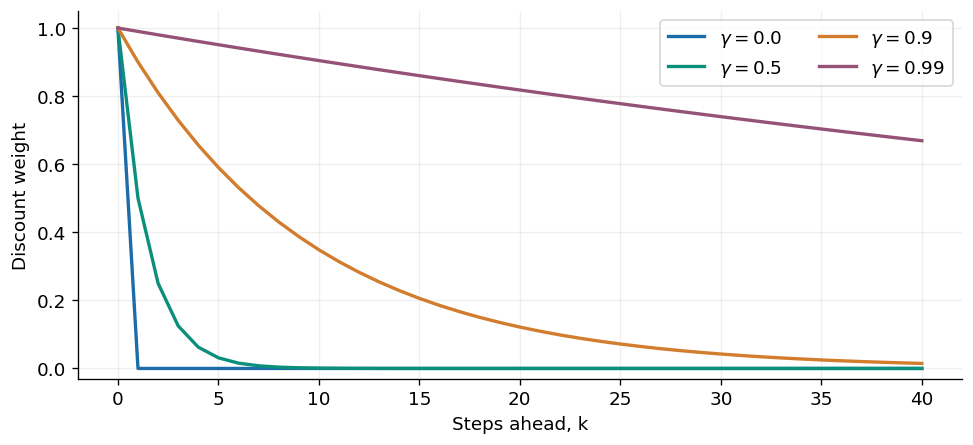

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
k = np.arange(41)
for gamma, color in zip([0.0, 0.5, 0.9, 0.99], COLORS):
    ax.plot(k, gamma ** k, label=fr"$\gamma={gamma}$", color=color, linewidth=2)
ax.set(xlabel="Steps ahead, k", ylabel="Discount weight", ylim=(-0.03, 1.05))
ax.legend(ncol=2)
plt.show()

### 2.3.3 状態価値関数：収益の期待値

方策や状態遷移が確率的なら、同じ状態から始めても収益は変わりうる。そこで、起こりうる収益をその確率で重み付けして平均したものを計算する。これが期待値である。

説明用に、収益 $4$ が確率 $1/4$、収益 $0$ が確率 $3/4$ で得られる場合を考える。

$$
E[G]=\frac14\times4+\frac34\times0=1.
$$

$1$ は個々の試行で必ず得られる値ではない。何度も同じ条件で試したときの平均に対応する。

ここで、状態 $s$ から方策 $\pi$ に従ったときの収益の期待値を状態価値関数と呼ぶ。

$$
v_\pi(s)=E[G_t\mid S_t=s,\pi] \tag{2.2}
$$

縦棒 $\mid$ は「右側の条件のもとで」という意味である。状態を $s$ に固定し、その後の行動は方策 $\pi$ に従う。環境の遷移も確率的なら、そのばらつきも期待値に含める。同じ意味を、方策を $E$ の下付きとして書く。

$$
v_\pi(s)=E_\pi[G_t\mid S_t=s] \tag{2.3}
$$

| 量 | 何を表すか | この資料での扱い |
|---|---|---|
| $R_t$ | あるステップの報酬 | 遷移表から取得する |
| $G_t$ | ある軌跡で得る割引報酬の和 | 報酬列から計算する |
| $v_\pi(s)$ | 同じ開始状態・方策での収益の期待値 | 計算によって求める |
| $V_\pi(s)$ | 状態価値の推定値 | 有限回の試行の平均などで近似する |

次の節では、環境と方策をともに決定論的にして収益と期待値が一致する例を計算する。

### 2.3.4 最適方策と最適価値関数

方策の良さは開始状態ごとの価値で比較する。方策 $\pi'$ が $\pi$ と同等以上である条件は、すべての状態で価値が同等以上になることである。

$$
v_{\pi'}(s)\geq v_\pi(s)\qquad\text{for every }s.
$$

ある状態では $\pi'$ が高く、別の状態では $\pi$ が高い場合、この基準では優劣をつけられない。状態ごとの価値を平均してしまうと、開始状態の扱いを別に決めたことになる。

最適方策 $\pi_*$ はどの方策と比較しても、すべての状態で価値が同等以上になる方策である。等号も認めるため、最適方策が複数ある場合もある。

$$
v_{\pi_*}(s)\geq v_\pi(s)\qquad\text{for every }s\text{ and every }\pi.
$$

ここで扱う、状態・行動が有限、報酬が有界、$0\leq\gamma<1$ の MDP では、決定論的で時刻に依存しない最適方策を少なくとも 1 つ選べる。決定論的方策は、状態から行動が 1 つに決まる関数 $a=\mu(s)$ である。

この事実を使うと、今回の最適方策は決定論的な方策をすべて比べることで見つけ出せる。ただし、状態数が増えると全列挙は難しくなる。

## 2.4 MDP の例：2 マスのグリッドワールド

状態は左の $L1$ と右の $L2$、行動は左と右の 2 種類である。移動は決定論的で、壁に向かうと位置は変わらず、報酬 $-1$ を受け取る。

$L1$ から $L2$ に移るとリンゴを得て、報酬は $+1$ になる。$L2$ から $L1$ に戻ると報酬は $0$ で、リンゴが再び現れる。$L2$ から右の壁へ進んでもリンゴは現れない。この規則では位置だけで次の遷移と報酬が決まるため、リンゴの有無を別の状態変数として持つ必要はない。

| 現在の状態 | 行動 | 次の状態 | 報酬 |
|---|---|---|---|
| $L1$ | 左 | $L1$ | $-1$ |
| $L1$ | 右 | $L2$ | $+1$ |
| $L2$ | 左 | $L1$ | $0$ |
| $L2$ | 右 | $L2$ | $-1$ |

これは連続タスクであり、$L2$ は終了状態ではない。リンゴを取った後も行動と報酬が続く。

コードでは状態を `0 = L1`、`1 = L2`、行動を `0 = 左`、`1 = 右` と表す。`NEXT_STATE[s, a]` と `REWARD[s, a]` は表の 1 行を選択するための配列である。今回の遷移先は一意なので、報酬関数の引数 $s'$ は配列の添字から省ける。

In [6]:
STATE_NAMES = np.array(["L1", "L2"])
ACTION_NAMES = np.array(["左", "右"])
NEXT_STATE = np.array([[0, 1], [0, 1]], dtype=np.int64)
REWARD = np.array([[-1.0, 1.0], [0.0, -1.0]])

class TwoStateWorld:
    # 教科書の 2 マスの例に合わせて作成した教材用のクラスである。
    def reset(self, start=0):
        if start not in (0, 1):
            raise ValueError("開始状態は 0 または 1 で指定する")
        self.state = int(start)
        return self.state

    def step(self, action):
        if action not in (0, 1):
            raise ValueError("行動は 0 または 1 で指定する")
        state = self.state
        next_state = int(NEXT_STATE[state, action])
        reward = float(REWARD[state, action])
        self.state = next_state  # 状態を更新し、次の行動はこの状態で選ぶ。
        return next_state, reward  # 連続タスクなので、終了フラグは設けない。

display(pd.DataFrame(NEXT_STATE, index=STATE_NAMES, columns=ACTION_NAMES))
display(pd.DataFrame(REWARD, index=STATE_NAMES, columns=ACTION_NAMES))
env = TwoStateWorld()
s = env.reset(start=0)
a = 1
s_next, reward = env.step(a)
print("s =", s, ", a =", a, ", s_next =", s_next, ", reward =", reward)
print("更新後の env.state =", env.state)

,左,右
L1,0,1
L2,0,1


,左,右
L1,-1.0,1.0
L2,0.0,-1.0


s = 0 , a = 1 , s_next = 1 , reward = 1.0
更新後の env.state = 1


上の 1 ステップでは、`s = 0` から `a = 1` を選び、`s_next = 1`、`reward = 1.0` を得る。`env.state` も `1` に更新される。配列の形はどちらも `(2, 2)` で、第 1 軸が状態、第 2 軸が行動である。`NEXT_STATE` の値は状態の番号、`REWARD` の値は報酬であり、意味が異なる。

### 2.4.1 バックアップ線図

バックアップ線図は状態から行動を選び、報酬を受け取って次の状態に進む関係を、矢印で表した図である。以下では、状態を丸、行動と報酬を矢印のラベルで示す簡略図を描く。下向きに時間が進む。

各状態で左と右を確率 $1/2$ で選ぶと、$L1$ から 2 ステップ後までに 4 本の経路ができる。今回の環境は決定論的なので、分岐を生むのは方策である。別の MDP では、1 つの行動を選んだ後に、環境の遷移確率でさらに分岐する場合もある。

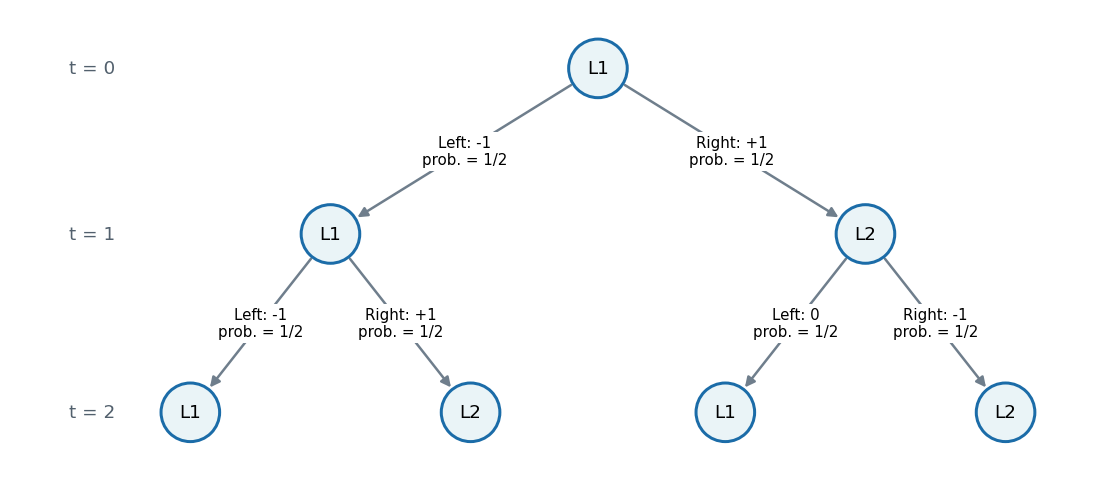

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
nodes = [(0, 2.8, "L1"), (-2.1, 1.5, "L1"), (2.1, 1.5, "L2"),
         (-3.2, 0.1, "L1"), (-1.0, 0.1, "L2"),
         (1.0, 0.1, "L1"), (3.2, 0.1, "L2")]
edges = [(0, 1, "Left: -1"), (0, 2, "Right: +1"),
         (1, 3, "Left: -1"), (1, 4, "Right: +1"),
         (2, 5, "Left: 0"), (2, 6, "Right: -1")]
for parent, child, label in edges:
    x1, y1, _ = nodes[parent]
    x2, y2, _ = nodes[child]
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), shrinkA=19, shrinkB=19,
                                arrowstyle="-|>", mutation_scale=12,
                                linewidth=1.5, color="#6F7E8C"))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, label + "\nprob. = 1/2",
            ha="center", va="center", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=2))
for x, y, label in nodes:
    ax.add_patch(Circle((x, y), 0.23, facecolor="#EAF4F7", edgecolor=COLORS[0], lw=1.8))
    ax.text(x, y, label, ha="center", va="center")
for y, label in [(2.8, "t = 0"), (1.5, "t = 1"), (0.1, "t = 2")]:
    ax.text(-4.15, y, label, va="center", color="#52606D")
ax.set(xlim=(-4.6, 3.8), ylim=(-0.4, 3.25))
ax.set_aspect("equal")
ax.axis("off")
plt.show()

図のラベルは「行動：その遷移の報酬」を表す。`prob. = 1/2` は行動を選ぶ確率を示す。環境の遷移先は一意に決まる。同じ $L1$ が複数描かれているのは、異なる経路・時刻で同じ状態に戻るためであり、状態の種類が増えたわけではない。

2 ステップだけの収益を計算すると、期待値を「経路の重み付き平均」として確認できる。各経路の確率は $(1/2)\times(1/2)=1/4$ である。`paths` には経路ごとの 2 つの報酬、確率、有限収益が格納される。

In [8]:
paths = []
for a0 in (0, 1):
    for a1 in (0, 1):
        s0 = 0
        s1 = int(NEXT_STATE[s0, a0])
        s2 = int(NEXT_STATE[s1, a1])
        r0 = REWARD[s0, a0]
        r1 = REWARD[s1, a1]
        g0 = r0 + GAMMA * r1
        paths.append({"最初の行動": ACTION_NAMES[a0], "次の行動": ACTION_NAMES[a1],
                      "経路": f"L1 → {STATE_NAMES[s1]} → {STATE_NAMES[s2]}",
                      "R_0": r0, "R_1": r1, "確率": 0.25,
                      "2 ステップの収益": g0})
paths = pd.DataFrame(paths)
paths["確率 × 収益"] = paths["確率"] * paths["2 ステップの収益"]
display(paths)
print("2 ステップの収益の期待値：", paths["確率 × 収益"].sum())

,最初の行動,次の行動,経路,R_0,R_1,確率,2 ステップの収益,確率 × 収益
0,左,左,L1 → L1 → L1,-1.0,-1.0,0.25,-1.9,-0.475
1,左,右,L1 → L1 → L2,-1.0,1.0,0.25,-0.1,-0.025
2,右,左,L1 → L2 → L1,1.0,0.0,0.25,1.0,0.250
3,右,右,L1 → L2 → L2,1.0,-1.0,0.25,0.1,0.025


2 ステップの収益の期待値： -0.225


4 通りの有限収益は $-1.9,-0.1,1,0.1$ である。期待値は、

$$
E_\pi[G_0^{(2)}\mid S_0=L1]
=\frac14(-1.9-0.1+1+0.1)=-0.225.
$$

これは最初の 2 ステップだけの期待値であり、無限に続けた状態価値 $v_\pi(L1)$ とは区別する。

### 2.4.2 最適方策：4 通りを比較する

決定論的で時刻に依存しない方策では、$L1$ と $L2$ のそれぞれに行動を 1 つ割り当てる。状態ごとに 2 通りの選択肢があるため、全体では $2^2=4$ 通りになる。

| 教科書の方策 | $L1$ での行動 | $L2$ での行動 | 配列での表現 |
|---|---|---|---|
| $\mu_1$ | 右 | 右 | `[1, 1]` |
| $\mu_2$ | 右 | 左 | `[1, 0]` |
| $\mu_3$ | 左 | 右 | `[0, 1]` |
| $\mu_4$ | 左 | 左 | `[0, 0]` |

`policy[s]` から状態 `s` で選ぶ行動の番号が得られる。たとえば `[1, 0]` は「$L1$ では右、$L2$ では左」である。

`rollout` は方策に従う軌跡を作る関数である。ループの各回で、現在の状態から行動を引き、環境を 1 ステップ動かし、その結果を表に記録する。`horizon` は記録するステップ数で、環境の終了条件ではない。

In [9]:
POLICIES = {
    "mu1": np.array([1, 1], dtype=np.int64),
    "mu2": np.array([1, 0], dtype=np.int64),
    "mu3": np.array([0, 1], dtype=np.int64),
    "mu4": np.array([0, 0], dtype=np.int64),
}

def rollout(policy, start, horizon):
    env = TwoStateWorld()
    state = env.reset(start)
    rows = []
    for t in range(horizon):
        action = int(policy[state])
        next_state, reward = env.step(action)
        rows.append({"t": t, "state": state, "action": action,
                     "reward": reward, "next_state": next_state})
        state = next_state  # 次のステップでは、遷移後の状態から行動を選ぶ。
    return pd.DataFrame(rows)

trace = rollout(POLICIES["mu2"], start=0, horizon=6)
trace["state_name"] = STATE_NAMES[trace["state"].to_numpy()]
trace["action_name"] = ACTION_NAMES[trace["action"].to_numpy()]
trace["discount"] = GAMMA ** trace["t"].to_numpy()
trace["contribution"] = trace["discount"] * trace["reward"]
trace["partial_return"] = trace["contribution"].cumsum()
display(trace)

,t,state,action,reward,next_state,state_name,action_name,discount,contribution,partial_return
0,0,0,1,1.0,1,L1,右,1.00000,1.0000,1.0000
1,1,1,0,0.0,0,L2,左,0.90000,0.0000,1.0000
2,2,0,1,1.0,1,L1,右,0.81000,0.8100,1.8100
3,3,1,0,0.0,0,L2,左,0.72900,0.0000,1.8100
4,4,0,1,1.0,1,L1,右,0.65610,0.6561,2.4661
5,5,1,0,0.0,0,L2,左,0.59049,0.0000,2.4661


`mu2` では状態が `0 → 1 → 0 → 1 → …` と変わり、報酬は `1, 0, 1, 0, …` になる。表の先頭行は `policy[0] = 1`、`NEXT_STATE[0, 1] = 1`、`REWARD[0, 1] = 1.0` に対応する。次の行では `policy[1] = 0` をもとに、左へ戻る。

`discount` と `contribution` は同じ長さの列である。`partial_return` はその時刻までに足した収益で、将来の報酬はまだ含まない。

#### 右へ進み続ける (決定論的) 方策 $\mu_1$

$L1$ から始めると、最初に $+1$ を得た後、右の壁で $-1$ を受け続ける。環境と方策が決定論的なので、収益は毎回同じになり、その値が状態価値である。

$$
\begin{aligned}
v_{\mu_1}(L1)
&=1-\gamma-\gamma^2-\gamma^3-\cdots\\
&=1-\gamma(1+\gamma+\gamma^2+\cdots)\\
&=1-\frac{\gamma}{1-\gamma}\\
&=1-\frac{0.9}{0.1}=-8.
\end{aligned}
$$

括弧の中の $1+\gamma+\gamma^2+\cdots$ は、各項が直前の項の $\gamma$ 倍になる無限等比級数である。$0\leq\gamma<1$ のとき、この和は $1/(1-\gamma)$ になる。以下で、その理由を確かめる。

まず、最初の $H$ 項の和を $S_H$ と置き、その $\gamma$ 倍と並べる。

$$
\begin{aligned}
S_H&=1+\gamma+\gamma^2+\cdots+\gamma^{H-1},\\
\gamma S_H&=\gamma+\gamma^2+\cdots+\gamma^{H-1}+\gamma^H.
\end{aligned}
$$

上の式から下の式を引くと、共通する項が打ち消され、右辺には $1-\gamma^H$ が残る。左辺では $S_H$ をくくり出せるので、

$$
(1-\gamma)S_H=1-\gamma^H.
$$

両辺を $1-\gamma>0$ で割ると、

$$
S_H=\frac{1-\gamma^H}{1-\gamma}.
$$

$0\leq\gamma<1$ では、項の数 $H$ を限りなく増やすと $\gamma^H$ が $0$ に近づく。したがって、無限に足した和は有限個の和 $S_H$ の極限として次のように求められる。

$$
\begin{aligned}
1+\gamma+\gamma^2+\cdots
&=\lim_{H\to\infty}S_H\\
&=\lim_{H\to\infty}\frac{1-\gamma^H}{1-\gamma}\\
&=\frac{1-0}{1-\gamma}\\
&=\frac{1}{1-\gamma}.
\end{aligned}
$$

この結果を括弧の中の和に代入すると、状態価値の式を次のように変形できる。

$$
\begin{aligned}
v_{\mu_1}(L1)
&=1-\gamma\left(1+\gamma+\gamma^2+\cdots\right)\\
&=1-\gamma\frac{1}{1-\gamma}\\
&=1-\frac{\gamma}{1-\gamma}.
\end{aligned}
$$

$L2$ から始めると、最初から報酬はずっと $-1$ である。

$$
v_{\mu_1}(L2)=-(1+\gamma+\gamma^2+\cdots)
=-\frac{1}{1-\gamma}=-10.
$$

最初の報酬が $+1$ でも、将来の罰を含めると価値は負になる。

#### 左右を往復する (決定論的) 方策 $\mu_2$

$L1$ から始めると、報酬 $+1$ を $2$ ステップごとに得る。$1,\gamma^2,\gamma^4,\ldots$ は、公比が $\gamma^2$ の等比級数である。

$$
\begin{aligned}
v_{\mu_2}(L1)
&=1+\gamma(0)+\gamma^2(1)+\gamma^3(0)+\cdots\\
&=1+\gamma^2+\gamma^4+\cdots\\
&=\frac{1}{1-\gamma^2}
=\frac{1}{1-0.81}\approx5.263158.
\end{aligned}
$$

$L2$ から始めると、最初は報酬 $0$ で左に戻る。その後の報酬列は$L1$ から始めた場合を $1$ ステップ遅らせたものになる。

$$
\begin{aligned}
v_{\mu_2}(L2)
&=0+\gamma(1)+\gamma^2(0)+\gamma^3(1)+\cdots\\
&=\gamma(1+\gamma^2+\gamma^4+\cdots)\\
&=\frac{\gamma}{1-\gamma^2}\approx4.736842.
\end{aligned}
$$

`mu2` の 6 ステップの表で `partial_return` が約 $2.4661$ なのは、無限に続く往復の一部しか足していないためである。

#### 残りの $\mu_3$ と $\mu_4$

$\mu_3$ は両方の状態で壁へ向かう。どちらから始めても報酬列は $-1,-1,-1,\ldots$ なので、

$$
v_{\mu_3}(L1)=v_{\mu_3}(L2)=-\frac{1}{1-\gamma}=-10.
$$

$\mu_4$ は常に左へ進む。$L1$ からなら最初から壁にぶつかる。$L2$ からなら最初だけ報酬 $0$ で左に移り、その後は壁にぶつかる。

$$
\begin{aligned}
v_{\mu_4}(L1)&=-\frac{1}{1-\gamma}=-10,\\
v_{\mu_4}(L2)&=0-\gamma-\gamma^2-\cdots
=-\frac{\gamma}{1-\gamma}=-9.
\end{aligned}
$$

次のセルは以上の式を配列 `exact_values` にまとめ、100 ステップの軌跡から計算した `finite_values` と比べる。どちらも形は `(4, 2)` で、行が方策、列が開始状態である。

In [10]:
def closed_form_values(gamma):
    # 行は mu1、mu2、mu3、mu4、列は L1、L2 の順に並ぶ。
    if not 0 <= gamma < 1:
        raise ValueError("無限和の式では 0 以上 1 未満の割引率を使う")
    return np.array([
        [1 - gamma / (1 - gamma), -1 / (1 - gamma)],
        [1 / (1 - gamma ** 2), gamma / (1 - gamma ** 2)],
        [-1 / (1 - gamma), -1 / (1 - gamma)],
        [-1 / (1 - gamma), -gamma / (1 - gamma)],
    ])

HORIZON = 100
exact_values = closed_form_values(GAMMA)
finite_values = np.empty((4, 2))
# 方策、開始状態、時刻の 3 軸を持つ配列に報酬を保存する。
reward_cube = np.empty((4, 2, HORIZON))
for i, policy in enumerate(POLICIES.values()):
    for start in (0, 1):
        trajectory = rollout(policy, start=start, horizon=HORIZON)
        reward_sequence = trajectory["reward"].to_numpy()
        reward_cube[i, start, :] = reward_sequence
        finite_values[i, start] = discounted_returns(reward_sequence, GAMMA)[0]

# repeat は各方策名を 2 回ずつ並べ、tile は開始状態の並びを 4 回繰り返す。
# ravel で各行を順につなげて 1 次元の配列にし、表の列として渡す。
comparison = pd.DataFrame({
    "方策": np.repeat(list(POLICIES), 2),
    "開始状態": np.tile(STATE_NAMES, 4),
    "無限和の理論値": exact_values.ravel(),
    "100 ステップの有限和": finite_values.ravel(),
    "絶対誤差": np.abs(exact_values - finite_values).ravel(),
})
display(comparison)
tail_bound = GAMMA ** HORIZON / (1 - GAMMA)
print("打ち切り誤差の上限：", f"{tail_bound:.6f}")
print("reward_cube の形：", reward_cube.shape)
# 手計算で求めた価値と、軌跡から求めた有限収益が、打ち切り誤差の範囲で一致するか確認する。
assert np.max(np.abs(exact_values - finite_values)) <= tail_bound + 1e-12

,方策,開始状態,無限和の理論値,100 ステップの有限和,絶対誤差
0,mu1,L1,-8.000000,-7.999734,0.000266
1,mu1,L2,-10.000000,-9.999734,0.000266
2,mu2,L1,5.263158,5.263018,0.000140
3,mu2,L2,4.736842,4.736716,0.000126
4,mu3,L1,-10.000000,-9.999734,0.000266
5,mu3,L2,-10.000000,-9.999734,0.000266
6,mu4,L1,-10.000000,-9.999734,0.000266
7,mu4,L2,-9.000000,-8.999734,0.000266


打ち切り誤差の上限： 0.000266
reward_cube の形： (4, 2, 100)


`mu1` を $L1$ から 100 ステップ実行した値は約 $-7.999734$ であり、教科書の有限回の加算と対応する。理論値 $-8$ との差は残りの負の報酬をまだ足していないために生じる。

`reward_cube[1, 0, :6]` には、`mu2` を $L1$ から始めた最初の 6 報酬が入る。スライス `:6` は時刻の先頭 6 要素を取り出す指定である。

次の図は無限和から求めた価値を示す。横軸は開始状態、縦軸 `State value` は価値である。どちらの状態でも最も高い棒グラフの方策を探す。

mu2 を L1 から始めたときの最初の 6 報酬： [1. 0. 1. 0. 1. 0.]


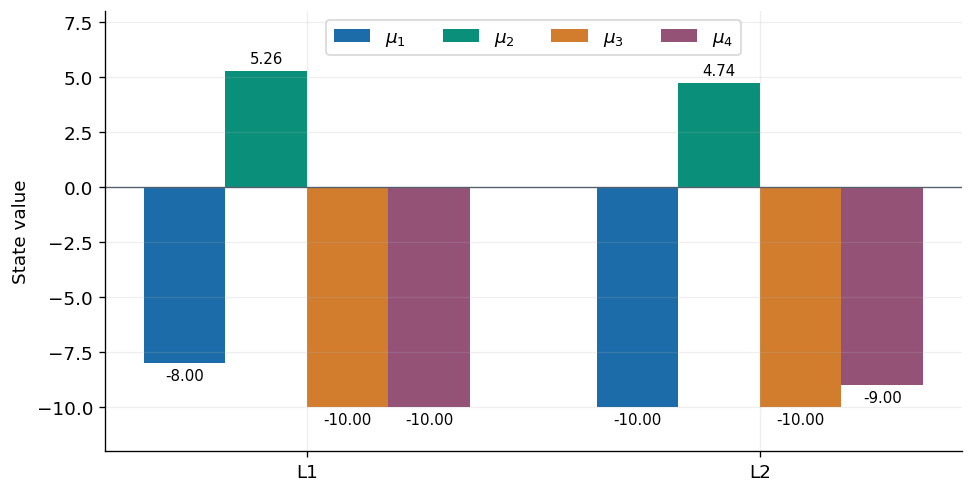

両方の状態で価値が最大となる方策： ['mu2']


In [11]:
print("mu2 を L1 から始めたときの最初の 6 報酬：", reward_cube[1, 0, :6])
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
x = np.arange(2)
width = 0.18
for i, color in enumerate(COLORS):
    bars = ax.bar(x + (i - 1.5) * width, exact_values[i], width,
                  color=color, label=fr"$\mu_{i + 1}$")
    ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=3)
ax.axhline(0, color="#52606D", linewidth=0.8)
ax.set(xticks=x, xticklabels=STATE_NAMES, ylabel="State value", ylim=(-12, 8))
ax.legend(ncol=4, loc="upper center")
plt.show()

# axis=1 を指定し、両方の開始状態で条件を満たすか確認する。
best_each_state = exact_values.max(axis=0)
is_optimal = np.all(np.isclose(exact_values, best_each_state), axis=1)
print("両方の状態で価値が最大となる方策：", np.array(list(POLICIES))[is_optimal])

この比較から、$\mu_2$ が最適方策となり、

$$
\mu_*(L1)=\mathrm{Right},\qquad \mu_*(L2)=\mathrm{Left},
$$

$$
v_*(L1)=\frac{1}{1-\gamma^2},\qquad
v_*(L2)=\frac{\gamma}{1-\gamma^2}
$$

を得る。$L1$ でリンゴを取り、$L2$ では報酬 $0$ を受け入れて左へ戻ることで、次のリンゴを得られる。

なお、$\mu_1$ と $\mu_4$ は優劣をつけられない。$L1$ では $-8>-10$ なので $\mu_1$ がよいが、$L2$ では $-10<-9$ なので $\mu_4$ がよい。「平均して高い方策」と「すべての状態で同等以上の方策」は異なる基準である。

ここで `max(axis=0)` は各状態の最大値を取り出すだけである。その最大値を 1 つの方策が同時に達成するかは、続く `np.all(..., axis=1)` で確認している。

## 2.5 まとめ

MDP では、環境の遷移と報酬を定め、方策に従って行動する。報酬を将来まで割引して足したものが収益であり、その期待値が状態価値関数である。最適方策はすべての状態で、ほかの方策と同等以上の価値を持つ。

2 マスの例では、4 通りの決定論的方策を比べて最適方策を求めた。状態が $n$ 個、各状態の行動が $m$ 個なら、決定論的で時刻に依存しない方策は $m^n$ 通りある。たとえば状態が 20 個、行動が 4 個なら $4^{20}=1{,}099{,}511{,}627{,}776$ 通りになる。次章のベルマン方程式は方策をすべて列挙する以外の解法を考えるための基礎となる。